In [23]:
import pandas as pd

clicks = pd.read_csv("../data/clean_clicks.csv")
hits = pd.read_csv("../data/clean_hits.csv")

print("Clicks:", len(clicks))
print("Hits:", len(hits))

Clicks: 2427
Hits: 1604


In [24]:
both = hits.groupby("participant").device.nunique()
both = both[both == 2].index

hits = hits[hits.participant.isin(both)]
clicks = clicks[clicks.participant.isin(both)]

print("Participants:", hits.participant.nunique())
print("Clicks:", len(clicks))
print("Hits:", len(hits))

Participants: 9
Clicks: 2233
Hits: 1444


In [25]:
cards = hits.groupby(["participant", "device", "A", "W", "ID"]).MT_ms.mean().reset_index()
print("Rows:", len(cards))
cards.head(9).round(2)

Rows: 162


,participant,device,A,W,ID,MT_ms
0,P0321,mouse,250,20,3.75,834.00
1,P0321,mouse,250,40,2.86,701.00
2,P0321,mouse,250,80,2.04,597.89
3,P0321,mouse,500,20,4.70,1081.44
4,P0321,mouse,500,40,3.75,917.44
5,P0321,mouse,500,80,2.86,731.00
6,P0321,mouse,900,20,5.52,1208.11
7,P0321,mouse,900,40,4.55,851.89
8,P0321,mouse,900,80,3.61,763.89


In [26]:
devcards = cards.groupby(["device", "A", "W", "ID"]).MT_ms.mean().reset_index()
devcards = devcards.sort_values(["device", "ID"])
devcards.round(2)

,device,A,W,ID,MT_ms
2,mouse,250,80,2.04,578.17
1,mouse,250,40,2.86,754.47
5,mouse,500,80,2.86,726.19
8,mouse,900,80,3.61,848.53
0,mouse,250,20,3.75,965.79
4,mouse,500,40,3.75,912.10
7,mouse,900,40,4.55,1044.39
3,mouse,500,20,4.70,1056.16
6,mouse,900,20,5.52,1350.95
11,phone,250,80,2.04,1044.05


In [27]:
import numpy as np

for device, group in devcards.groupby("device"):
    b, a = np.polyfit(group.ID, group.MT_ms, 1)
    r2 = np.corrcoef(group.ID, group.MT_ms)[0, 1] ** 2
    print(f"{device}: MT = {a:.0f} + {b:.0f} × ID   R² = {r2:.2f}")

mouse: MT = 141 + 207 × ID   R² = 0.97
phone: MT = -814 + 885 × ID   R² = 0.93


In [28]:
cards["TP"] = cards.ID / (cards.MT_ms / 1000)

tp = cards.groupby(["participant", "device"]).TP.mean().reset_index()
tp.round(2)

,participant,device,TP
0,P0321,mouse,4.33
1,P0321,phone,2.24
2,P0488,mouse,3.29
3,P0488,phone,0.96
4,P0908,mouse,2.92
5,P0908,phone,1.66
6,P1993,mouse,4.28
7,P1993,phone,1.60
8,P3398,mouse,5.87
9,P3398,phone,1.71


In [29]:
tp.groupby("device").TP.agg(["mean", "std", "count"]).round(2)

,mean,std,count
device,,,
mouse,4.30,0.91,9
phone,1.89,0.71,9


In [30]:
pairs = tp.pivot(index="participant", columns="device", values="TP").dropna()
pairs["difference"] = pairs.mouse - pairs.phone
pairs.round(2)

device,mouse,phone,difference
participant,,,
P0321,4.33,2.24,2.09
P0488,3.29,0.96,2.32
P0908,2.92,1.66,1.26
P1993,4.28,1.60,2.68
P3398,5.87,1.71,4.16
P3784,5.03,3.02,2.01
P4974,4.58,1.79,2.79
P6521,3.67,1.13,2.54
P7461,4.69,2.89,1.80


In [31]:
from scipy import stats

result = stats.ttest_rel(pairs.mouse, pairs.phone)
print(f"t = {result.statistic:.2f}, p = {result.pvalue:.5f}")

print(f"Mean difference = {pairs.difference.mean():.2f} bits/s")

t = 8.89, p = 0.00002
Mean difference = 2.41 bits/s


In [32]:
#error rates

In [33]:
clicks["error"] = 1 - clicks.hit

err = clicks.groupby(["participant", "device"]).error.mean().reset_index()
err.groupby("device").error.agg(["mean", "std", "count"]).round(3)

,mean,std,count
device,,,
mouse,0.104,0.073,9
phone,0.321,0.186,9


In [34]:
errW = clicks.groupby(["participant", "device", "W"]).error.mean().reset_index()
errW.groupby(["device", "W"]).error.mean().unstack().round(3)

W,20,40,80
device,,,
mouse,0.156,0.087,0.047
phone,0.411,0.256,0.205


In [35]:
#plots

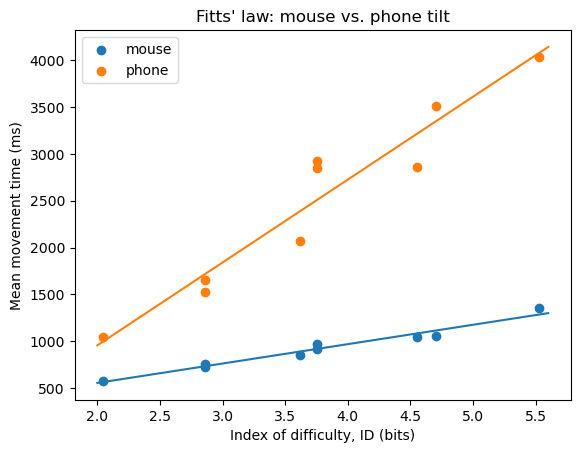

In [36]:
import matplotlib.pyplot as plt

for device, group in devcards.groupby("device"):
    b, a = np.polyfit(group.ID, group.MT_ms, 1)
    plt.scatter(group.ID, group.MT_ms, label=device)
    xs = np.array([2, 5.6])
    plt.plot(xs, a + b * xs)

plt.xlabel("Index of difficulty, ID (bits)")
plt.ylabel("Mean movement time (ms)")
plt.title("Fitts' law: mouse vs. phone tilt")
plt.legend()
plt.savefig("fitts_lines.png", dpi=200, bbox_inches="tight")
plt.show()

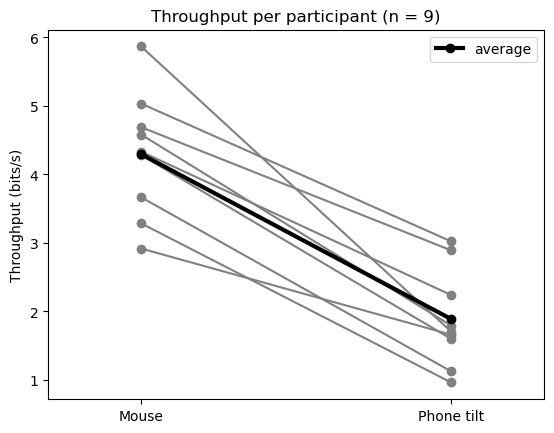

In [37]:
for name, row in pairs.iterrows():
    plt.plot([0, 1], [row.mouse, row.phone], color="grey", marker="o")

plt.plot([0, 1], [pairs.mouse.mean(), pairs.phone.mean()],
         color="black", marker="o", linewidth=3, label="average")

plt.xticks([0, 1], ["Mouse", "Phone tilt"])
plt.xlim(-0.3, 1.3)
plt.ylabel("Throughput (bits/s)")
plt.title("Throughput per participant (n = 9)")
plt.legend()
plt.savefig("throughput_pairs.png", dpi=200, bbox_inches="tight")
plt.show()

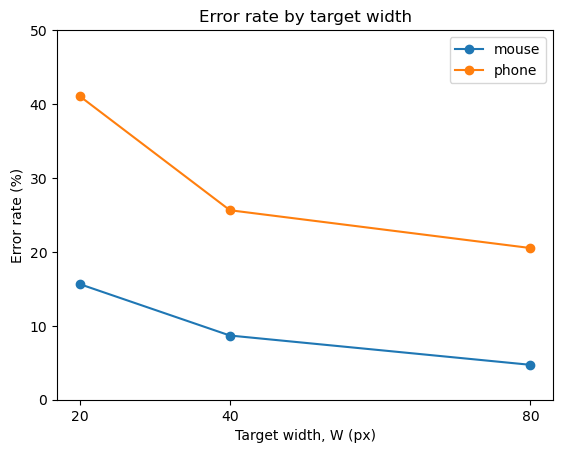

In [38]:
grid = errW.groupby(["device", "W"]).error.mean().reset_index()

for device, group in grid.groupby("device"):
    plt.plot(group.W, group.error * 100, marker="o", label=device)

plt.xticks([20, 40, 80])
plt.xlabel("Target width, W (px)")
plt.ylabel("Error rate (%)")
plt.ylim(0, 50)
plt.title("Error rate by target width")
plt.legend()
plt.savefig("errors_by_width.png", dpi=200, bbox_inches="tight")
plt.show()

In [39]:
import numpy as np

# E1: how far past (+) or short of (−) the target centre each click landed
clicks["direction"] = np.sign(clicks.targetX - 600)
clicks["dx"] = (clicks.clickX - clicks.targetX) * clicks.direction

# E2: leave out wrong-side clicks, then measure each card's spread
wrong_side = (clicks.clickX - (1200 - clicks.targetX)).abs() < (clicks.clickX - clicks.targetX).abs()
print("Wrong-side clicks:", wrong_side.sum())

aimed = clicks[~wrong_side]
spread = aimed.groupby(["participant", "device", "A", "W"]).dx.std().reset_index(name="sd")

cards = cards.merge(spread, on=["participant", "device", "A", "W"])
cards["We"] = 4.133 * cards.sd
cards.groupby(["device", "W"]).We.mean().unstack().round(1)

Wrong-side clicks: 12


W,20,40,80
device,,,
mouse,21.9,40.5,78.9
phone,56.4,66.1,117.2


In [40]:
from scipy import stats

cards["IDe"] = np.log2(cards.A / cards.We + 1)
cards["TPe"] = cards.IDe / (cards.MT_ms / 1000)

tpe = cards.groupby(["participant", "device"])[["TP", "TPe"]].mean().reset_index()
print(tpe.groupby("device")[["TP", "TPe"]].mean().round(2))

pairs_e = tpe.pivot(index="participant", columns="device", values="TPe").dropna()
pairs_e["difference"] = pairs_e.mouse - pairs_e.phone
result_e = stats.ttest_rel(pairs_e.mouse, pairs_e.phone)
print(f"t = {result_e.statistic:.2f}, p = {result_e.pvalue:.6f}, mean difference = {pairs_e.difference.mean():.2f}")
pairs_e.round(2)

          TP   TPe
device            
mouse   4.30  4.30
phone   1.89  1.61
t = 10.73, p = 0.000005, mean difference = 2.69


device,mouse,phone,difference
participant,,,
P0321,4.49,2.05,2.43
P0488,3.45,0.91,2.54
P0908,3.25,1.63,1.61
P1993,4.12,1.05,3.07
P3398,5.78,1.48,4.30
P3784,4.88,2.41,2.46
P4974,4.53,1.63,2.90
P6521,3.69,0.83,2.85
P7461,4.55,2.51,2.04


In [41]:
def compare(table, label):
    diff = table.mouse - table.phone
    r = stats.ttest_rel(table.mouse, table.phone)
    print(f"{label}: n = {len(table)}, mouse {table.mouse.mean():.2f}, phone {table.phone.mean():.2f}, "
          f"difference {diff.mean():.2f}, t = {r.statistic:.2f}, p = {r.pvalue:.5f}, "
          f"all faster with mouse: {(diff > 0).all()}")

mouse_input = clicks[clicks.device == "mouse"].groupby("participant").input.first()
mouse_users = mouse_input[mouse_input == "mouse"].index

compare(pairs_e, "All 9")
compare(pairs_e[pairs_e.index.isin(mouse_users)], "Mouse users only")
compare(pairs_e.drop("P1993"), "Without P1993")

All 9: n = 9, mouse 4.30, phone 1.61, difference 2.69, t = 10.73, p = 0.00000, all faster with mouse: True
Mouse users only: n = 4, mouse 4.21, phone 1.39, difference 2.81, t = 20.80, p = 0.00024, all faster with mouse: True
Without P1993: n = 8, mouse 4.33, phone 1.68, difference 2.64, t = 9.47, p = 0.00003, all faster with mouse: True


In [42]:
#heisenberg check

In [43]:
clicks["dy"] = clicks.clickY - 300
aimed = clicks[~wrong_side]

aimed.groupby("device")[["dx", "dy"]].agg(["mean", "std"]).round(1)

dx         dy      
       mean   std mean   std
device                      
mouse  -1.7  13.6  0.5   8.6
phone  -5.3  37.5  2.3  13.9

In [44]:
dy_person = aimed.groupby(["participant", "device"]).dy.mean().unstack().round(1)
print(dy_person)
print()
print("Pushed down (positive):", (dy_person > 0).sum().to_dict())
print("Pushed up (negative):  ", (dy_person < 0).sum().to_dict())

device       mouse  phone
participant              
P0321          2.4   -3.3
P0488          4.1    1.9
P0908         -0.1    0.7
P1993         -2.5    6.7
P3398          6.0    0.8
P3784         -2.8    2.0
P4974          0.4    2.8
P6521          0.2    6.2
P7461         -3.2   -6.1

Pushed down (positive): {'mouse': 5, 'phone': 7}
Pushed up (negative):   {'mouse': 4, 'phone': 2}
